# Лабораторная работа №8. Эпиполярная геометрия, disparity и глубина

Условие — в [методичке](CSE5382_15_лабораторных_работ_математические_методы_in_CV.md), раздел «Лабораторная работа №8».

**Данные.** `data/aloeL.jpg`, `data/aloeR.jpg` — ректифицированная стереопара из примеров OpenCV (растение алоэ на фоне ткани), уменьшенная вдвое до 641×555.

> **Оговорка о масштабе.** Калибровка к этой паре не приложена. Значения $f=1870$ px и $B=0.16$ м ниже взяты условно — только чтобы перевести disparity в метры и показать порядок величин. Абсолютные глубины поэтому иллюстративные. Все выводы о *чувствительности* (как ошибка disparity превращается в ошибку глубины) от выбора $f$ и $B$ не зависят: они входят в формулы общим множителем.

## 1. О чём эта работа

### Знакомый пример

Вытяните руку с поднятым пальцем и смотрите на него то левым, то правым глазом. Палец «прыгает» относительно фона. Поднесите палец к носу — прыжок станет большим. Посмотрите так же на дерево за окном — оно почти не сдвинется. Мозг по величине этого сдвига оценивает расстояние. Две камеры рядом делают то же самое.

### Основная идея

Две камеры смотрят параллельно и стоят на расстоянии $B$ друг от друга. Одна и та же точка сцены на левом снимке окажется правее, чем на правом. Величина сдвига в пикселях — **disparity**. Близкие предметы сдвигаются сильно, далёкие — слабо. Из сдвига по простой формуле получается расстояние.

### Понятия

- **Baseline** $B$ — расстояние между центрами камер.
- **Disparity** $d=x_L-x_R$ — разность горизонтальных координат одной и той же точки на левом и правом снимках, в пикселях.
- **Ректификация** — преобразование пары так, чтобы одна и та же точка сцены лежала на **одной строке** обоих снимков. После неё пару для пикселя нужно искать только вдоль строки, а не по всему кадру.
- **Эпиполярная линия.** Точка на левом снимке задаёт луч в пространстве. Проекция этого луча на правый снимок — прямая; пара точки обязана лежать на ней. У ректифицированной пары эпиполярные линии — строки изображения.
- **Фундаментальная матрица** $F$ (3×3) записывает это ограничение для любой, не обязательно ректифицированной пары камер: для пары точек выполняется $x'^TFx=0$.
- **Disparity map** — картинка, где в каждом пикселе записана его disparity. **Depth map** — картинка расстояний.
- **Block matching (StereoBM)** — для каждого окна левого снимка ищет самое похожее окно в той же строке правого. **Semi-global matching (StereoSGBM)** — дополнительно требует, чтобы соседние пиксели имели близкие disparity (плавность).

### Формулы

Эпиполярное ограничение: $x'^TFx=0$, где $x=(x_L,y_L,1)$, $x'=(x_R,y_R,1)$.

Глубина — из подобия треугольников:

$$Z=\frac{fB}{d}$$

$f$ — фокусное в пикселях (лабораторная 7), $B$ — baseline в метрах, $d$ — disparity в пикселях, $Z$ — расстояние в метрах.

Чувствительность — производная глубины по disparity:

$$\left|\frac{dZ}{dd}\right|=\frac{fB}{d^2}=\frac{Z^2}{fB},\qquad \sigma_Z\approx\frac{fB}{d^2}\,\sigma_d$$

$\sigma_d$ — погрешность disparity (обычно доли пикселя), $\sigma_Z$ — получающаяся погрешность глубины. Вторая форма записи, $Z^2/(fB)$, показывает главное: **ошибка глубины растёт как квадрат расстояния**.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "image.cmap": "gray"})

LEFT, RIGHT = "data/aloeL.jpg", "data/aloeR.jpg"
F_PX = 1870.0        # условное фокусное, px (см. оговорку)
BASELINE_M = 0.16    # условный baseline, м
MIN_DISP, NUM_DISP = 16, 96
cv2.setRNGSeed(0)

## 2. Вопрос 1 — глубина по disparity

> При f=900 px, B=0.12 m, d=54 px найдите глубину Z.

$$Z=\frac{fB}{d}=\frac{900\cdot0.12}{54}=\frac{108}{54}=2\ \text{м}$$

**Проверка единиц:** пиксели × метры / пиксели = метры.

**Смысл.** Произведение $fB=108$ px·м — константа стереопары. Точка на расстоянии 1 м дала бы disparity 108 px, на 2 м — 54 px, на 4 м — 27 px: каждое удвоение расстояния делит disparity пополам.

In [2]:
f, B, d = 900.0, 0.12, 54.0
print("fB =", f * B, "px·м;  Z =", f * B / d, "м")
for Z in (1, 2, 4, 8, 16):
    print(f"  Z = {Z:2d} м → d = {f * B / Z:6.2f} px")

fB = 108.0 px·м;  Z = 2.0 м
  Z =  1 м → d = 108.00 px
  Z =  2 м → d =  54.00 px
  Z =  4 м → d =  27.00 px
  Z =  8 м → d =  13.50 px
  Z = 16 м → d =   6.75 px


**Итог вопроса 1:** $Z=2.0$ м.

## 3. Вопрос 2 — погрешность глубины

> При f=900, B=0.12, d=18, σ_d=0.5 px оцените σ_Z. Объясните, во сколько раз возрастёт чувствительность, если disparity уменьшится в два раза.

**Шаг 1. Глубина:** $Z=108/18=6$ м.

**Шаг 2. Чувствительность.** $Z=fB\cdot d^{-1}$, производная: $dZ/dd=-fB\cdot d^{-2}$. По модулю:

$$\left|\frac{dZ}{dd}\right|=\frac{108}{18^2}=\frac{108}{324}=0.3333\ \text{м/px}$$

Ошибка disparity в один пиксель сдвигает оценку глубины на 33 см.

**Шаг 3. Погрешность.** $\sigma_Z\approx0.3333\cdot0.5\approx0.167$ м — около 17 см при расстоянии 6 м (2.8 %).

**Шаг 4. Если $d$ уменьшится вдвое** (точка вдвое дальше, $d=9$, $Z=12$ м): в знаменателе $d^2$, оно уменьшается в 4 раза, значит чувствительность **возрастает в 4 раза**: $108/81=1.333$ м/px, $\sigma_Z\approx0.667$ м.

**Смысл.** Знак минус в производной — «disparity больше → глубина меньше». Сравним с вопросом 1: там $d=54$, $Z=2$ м, чувствительность $108/54^2=0.037$ м/px. Точка в 3 раза дальше — чувствительность в 9 раз выше. Стереокамера точна вблизи и быстро теряет точность с расстоянием.

**Насколько честна линейная оценка.** Формула $\sigma_Z\approx|dZ/dd|\sigma_d$ — приближение для малых ошибок. Точно: $Z(17.5)=6.171$, $Z(18.5)=5.838$ — отклонения $+0.171$ и $-0.162$ м. Ошибка несимметрична: недооценка disparity дороже переоценки.

In [3]:
f, B, d, sd = 900.0, 0.12, 18.0, 0.5
Z = f * B / d
sens = f * B / d ** 2
print(f"Z = {Z} м, |dZ/dd| = {sens:.4f} м/px, σ_Z ≈ {sens * sd:.4f} м ({100 * sens * sd / Z:.1f} % от Z)")
print(f"при d/2 = {d / 2}: Z = {f * B / (d / 2)} м, |dZ/dd| = {f * B / (d / 2) ** 2:.4f} м/px — в {(f * B / (d / 2) ** 2) / sens:.0f} раза больше")
print(f"точно: Z(d−σ) − Z = {f * B / (d - sd) - Z:+.4f} м, Z(d+σ) − Z = {f * B / (d + sd) - Z:+.4f} м")
print(f"через Z: Z²/(fB) = {Z ** 2 / (f * B):.4f} м/px — та же чувствительность")

Z = 6.0 м, |dZ/dd| = 0.3333 м/px, σ_Z ≈ 0.1667 м (2.8 % от Z)
при d/2 = 9.0: Z = 12.0 м, |dZ/dd| = 1.3333 м/px — в 4 раза больше
точно: Z(d−σ) − Z = +0.1714 м, Z(d+σ) − Z = -0.1622 м
через Z: Z²/(fB) = 0.3333 м/px — та же чувствительность


**Итог вопроса 2:** $\sigma_Z\approx0.167$ м; при уменьшении disparity вдвое чувствительность возрастает в 4 раза.

## 4. Задание 3 — код и эксперимент

### Шаги 1–2. Стереопара и grayscale

Пара уже ректифицирована. Проверить это можно глазами: одна и та же деталь должна находиться на одной высоте на обоих снимках (красные линии). Численная проверка — в шаге 10.

размер: (641, 555)


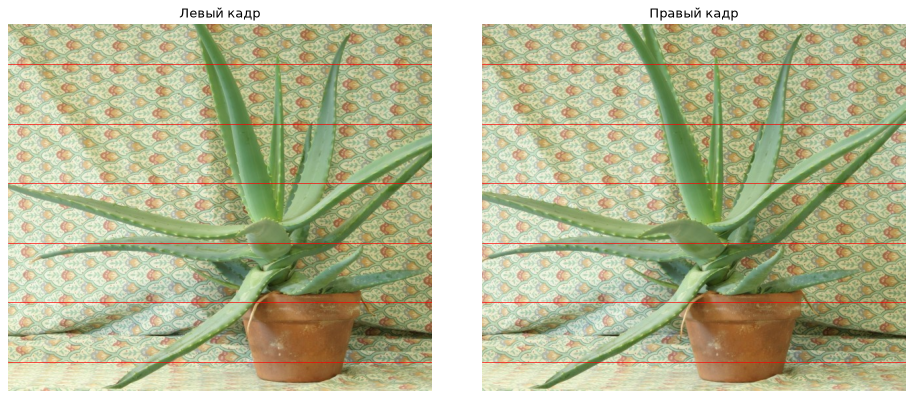

In [4]:
left_bgr, right_bgr = cv2.imread(LEFT), cv2.imread(RIGHT)
left_gray = cv2.cvtColor(left_bgr, cv2.COLOR_BGR2GRAY)
right_gray = cv2.cvtColor(right_bgr, cv2.COLOR_BGR2GRAY)
H, W = left_gray.shape
print("размер:", (W, H))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, im, title in zip(ax, (left_bgr, right_bgr), ("Левый кадр", "Правый кадр")):
    a.imshow(im[..., ::-1]); a.set_title(title); a.axis("off")
    for yy in range(60, H, 90): a.axhline(yy, color="r", lw=0.6)
plt.tight_layout(); plt.show()

### Шаги 3–6. StereoBM и StereoSGBM, масштаб disparity, невалидные пиксели

Два технических момента.

**Масштаб.** OpenCV возвращает disparity целыми числами, умноженными на 16 (4 бита отведены под дробную часть — субпиксельная точность 1/16 px). Поэтому результат делим на 16.

**Невалидные пиксели.** Там, где пару найти не удалось, OpenCV записывает значение `minDisparity − 1`. При `minDisparity = 0` это −1, отсюда правило методички «удалить $d\le0$». Мы ищем disparity в диапазоне 16…112 (ближе 16 px в сцене ничего нет), поэтому невалидное значение у нас — 15, и условие валидности: `disp >= MIN_DISP`. Формально $d=15>0$, и без этой поправки невалидные пиксели получили бы «глубину» $fB/15$.

метод                         плотность, %   шум, %      d min..max
BM, block=9                           79.4     4.15     16.0..111.0
BM, block=15                          76.3     1.79     18.3..111.0
BM, block=21                          72.3     1.32     16.0..107.8
SGBM, block=3                         88.6     0.89     21.0..105.9
SGBM, block=5                         88.8     0.68     22.1..105.9
SGBM, block=9                         88.6     0.47     22.6..106.1
SGBM, block=5, numDisp=64             89.8     0.66      16.0..79.0

пикселей с d > 80 (по эталонной SGBM): 0.4 % кадра
  при numDisp=64 из них без ответа: 59.9 %; у остальных медианная ошибка disparity = 17.6 px


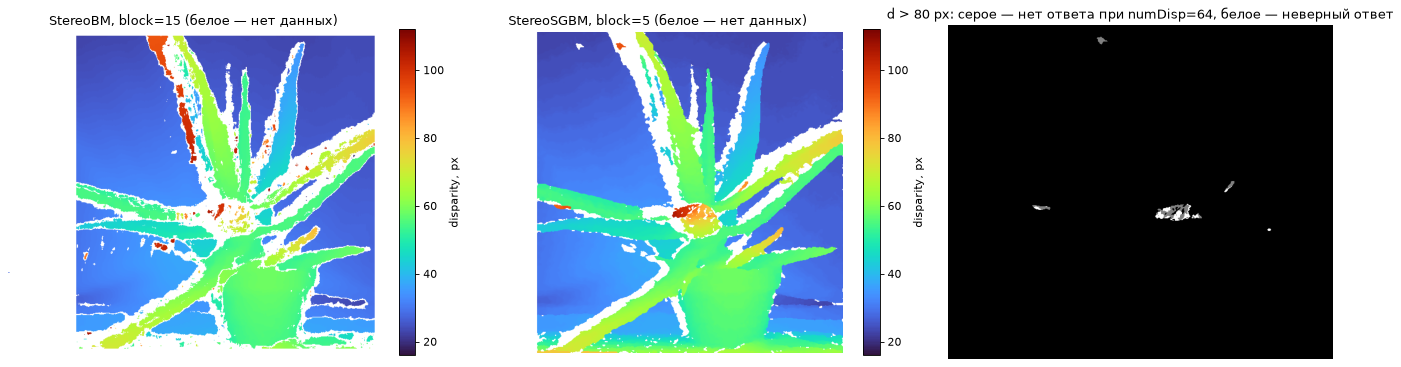

In [5]:
def run_bm(block):
    bm = cv2.StereoBM_create(numDisparities=NUM_DISP, blockSize=block)
    bm.setMinDisparity(MIN_DISP)
    return bm.compute(left_gray, right_gray).astype(np.float32) / 16.0

def run_sgbm(block, num_disp=NUM_DISP):
    sgbm = cv2.StereoSGBM_create(minDisparity=MIN_DISP, numDisparities=num_disp, blockSize=block,
                                 P1=8 * block * block, P2=32 * block * block,
                                 disp12MaxDiff=1, uniquenessRatio=10, speckleWindowSize=100, speckleRange=2)
    return sgbm.compute(left_gray, right_gray).astype(np.float32) / 16.0

def stats(disp, min_disp=MIN_DISP, num_disp=NUM_DISP):
    """Плотность валидной карты и шум: доля валидных пикселей, отличающихся от медианы 5×5 больше чем на 1 px."""
    valid = disp >= min_disp
    region = np.zeros_like(valid); region[:, min_disp + num_disp:] = True     # левая полоса не может иметь пары
    med = cv2.medianBlur(np.where(valid, disp, 0).astype(np.float32), 5)
    noisy = (np.abs(disp - med) > 1.0) & valid
    return 100 * valid[region].mean(), 100 * noisy.sum() / max(valid.sum(), 1), valid

results = {
    "BM, block=9": run_bm(9),
    "BM, block=15": run_bm(15),
    "BM, block=21": run_bm(21),
    "SGBM, block=3": run_sgbm(3),
    "SGBM, block=5": run_sgbm(5),
    "SGBM, block=9": run_sgbm(9),
    "SGBM, block=5, numDisp=64": run_sgbm(5, 64),
}
print(f"{'метод':28}{'плотность, %':>14}{'шум, %':>9}{'d min..max':>16}")
for name, disp in results.items():
    nd = 64 if "numDisp=64" in name else NUM_DISP
    dens, noise, valid = stats(disp, num_disp=nd)
    print(f"{name:28}{dens:14.1f}{noise:9.2f}{f'{disp[valid].min():.1f}..{disp[valid].max():.1f}':>16}")

disp_bm, disp = results["BM, block=15"], results["SGBM, block=5"]
valid_bm, valid = disp_bm >= MIN_DISP, disp >= MIN_DISP

# что происходит с ближними пикселями (d > 80), если диапазон поиска обрезан до 16..80
d64 = results["SGBM, block=5, numDisp=64"]
near_px = valid & (disp > MIN_DISP + 64)
got = near_px & (d64 >= MIN_DISP)
print(f"\nпикселей с d > {MIN_DISP + 64} (по эталонной SGBM): {100 * near_px.mean():.1f} % кадра")
print(f"  при numDisp=64 из них без ответа: {100 * (1 - got.sum() / near_px.sum()):.1f} %; у остальных медианная ошибка disparity = {np.median(np.abs(d64[got] - disp[got])):.1f} px")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for a, (dm, vm, title) in zip(ax, [(disp_bm, valid_bm, "StereoBM, block=15"), (disp, valid, "StereoSGBM, block=5")]):
    im = a.imshow(np.where(vm, dm, np.nan), cmap="turbo", vmin=MIN_DISP, vmax=MIN_DISP + NUM_DISP); a.set_title(title + " (белое — нет данных)"); a.axis("off")
    plt.colorbar(im, ax=a, fraction=0.04, label="disparity, px")
ax[2].imshow(np.where(near_px, np.where(got, 1.0, 0.5), 0.0), cmap="gray"); ax[2].set_title("d > 80 px: серое — нет ответа при numDisp=64, белое — неверный ответ"); ax[2].axis("off")
plt.tight_layout(); plt.show()

«Плотность» — доля пикселей с найденной disparity. Считается без левой полосы шириной `minDisparity + numDisparities`: для пикселей у левого края левого кадра пара на правом кадре находилась бы за его границей, и найти её нельзя в принципе.

При `numDisparities=64` диапазон поиска 16…80 px, а у самых ближних листьев disparity больше 80. Таких пикселей мало (0.4 % кадра), поэтому общая плотность почти не меняется, но для них результат плохой: около 60 % остались без ответа, а остальным алгоритм приписал disparity с ошибкой ≈ 18 px — то есть уверенно выдал неверное расстояние. Диапазон поиска обязан покрывать самый близкий объект сцены.

### Шаг 7. Depth = fB/d

fB = 299.2 px·м (условные f и B)
глубина: min = 2.83 м, медиана = 9.39 м, max = 13.56 м


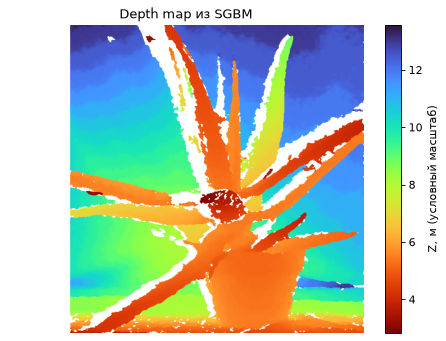

In [6]:
depth = np.full_like(disp, np.nan, dtype=np.float32)
depth[valid] = F_PX * BASELINE_M / disp[valid]
print(f"fB = {F_PX * BASELINE_M:.1f} px·м (условные f и B)")
print(f"глубина: min = {np.nanmin(depth):.2f} м, медиана = {np.nanmedian(depth):.2f} м, max = {np.nanmax(depth):.2f} м")

plt.figure(figsize=(7, 5))
im = plt.imshow(depth, cmap="turbo_r"); plt.colorbar(im, fraction=0.04, label="Z, м (условный масштаб)")
plt.title("Depth map из SGBM"); plt.axis("off"); plt.show()

### Шаги 8–9. Десять точек: Z(d−1), Z(d), Z(d+1)

Точки выбираются воспроизводимо: 10 квантилей распределения disparity от ближних объектов (большая $d$) к дальним (малая $d$); для каждого берётся пиксель с ближайшим значением.

Точка       (x,y)    d, px   Z(d−1), m   Z(d), m   Z(d+1), m   |ΔZ| на ±1px, m   fB/d², m/px
    1   (636,173)    75.62      4.0094    3.9564      3.9047            0.0523        0.0523
    2   (347,210)    57.88      5.2607    5.1698      5.0820            0.0894        0.0893
    3   (622,203)    54.12      5.6320    5.5279      5.4277            0.1022        0.1021
    4   (312,114)    43.81      6.9886    6.8291      6.6767            0.1560        0.1559
    5    (511,19)    34.00      9.0667    8.8000      8.5486            0.2590        0.2588
    6   (306,188)    30.31     10.2072    9.8705      9.5553            0.3260        0.3256
    7   (291,117)    28.06     11.0559   10.6619     10.2951            0.3804        0.3799
    8    (267,62)    26.00     11.9680   11.5077     11.0815            0.4433        0.4426
    9     (299,0)    24.06     12.9734   12.4343     11.9382            0.5176        0.5167
   10     (157,0)    23.00     13.6000   13.0087     12.4667          

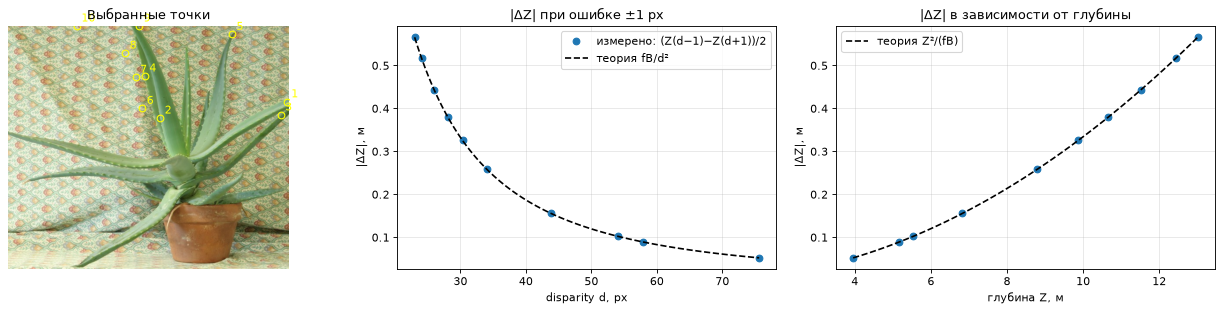

отношение |ΔZ| самой дальней точки к самой ближней: 10.8; отношение глубин: 3.29, его квадрат: 10.8


In [7]:
ys, xs = np.nonzero(valid)
dv = disp[valid]
quantiles = np.linspace(0.99, 0.01, 10)
rows = []
for q in quantiles:
    target = np.quantile(dv, q)
    i = np.argmin(np.abs(dv - target))
    rows.append((xs[i], ys[i], dv[i]))

fb = F_PX * BASELINE_M
print(f"{'Точка':>5}{'(x,y)':>12}{'d, px':>9}{'Z(d−1), m':>12}{'Z(d), m':>10}{'Z(d+1), m':>12}{'|ΔZ| на ±1px, m':>18}{'fB/d², m/px':>14}")
table = []
for n, (x, y, dd) in enumerate(rows, 1):
    zm, z0, zp = fb / (dd - 1), fb / dd, fb / (dd + 1)
    dz = (zm - zp) / 2
    table.append((dd, z0, dz))
    print(f"{n:5d}{f'({x},{y})':>12}{dd:9.2f}{zm:12.4f}{z0:10.4f}{zp:12.4f}{dz:18.4f}{fb / dd ** 2:14.4f}")

table = np.array(table)
dline = np.linspace(table[:, 0].min(), table[:, 0].max(), 100)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].imshow(left_bgr[..., ::-1]); ax[0].axis("off"); ax[0].set_title("Выбранные точки")
for n, (x, y, dd) in enumerate(rows, 1):
    ax[0].plot(x, y, "o", mfc="none", mec="yellow"); ax[0].annotate(str(n), (x, y), color="yellow", fontsize=10, xytext=(4, 4), textcoords="offset points")
ax[1].plot(table[:, 0], table[:, 2], "o", label="измерено: (Z(d−1)−Z(d+1))/2"); ax[1].plot(dline, fb / dline ** 2, "k--", label="теория fB/d²")
ax[1].set(title="|ΔZ| при ошибке ±1 px", xlabel="disparity d, px", ylabel="|ΔZ|, м"); ax[1].legend(); ax[1].grid(alpha=0.3)
ax[2].plot(table[:, 1], table[:, 2], "o"); zl = np.linspace(table[:, 1].min(), table[:, 1].max(), 100); ax[2].plot(zl, zl ** 2 / fb, "k--", label="теория Z²/(fB)")
ax[2].set(title="|ΔZ| в зависимости от глубины", xlabel="глубина Z, м", ylabel="|ΔZ|, м"); ax[2].legend(); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"отношение |ΔZ| самой дальней точки к самой ближней: {table[-1, 2] / table[0, 2]:.1f}; отношение глубин: {table[-1, 1] / table[0, 1]:.2f}, его квадрат: {(table[-1, 1] / table[0, 1]) ** 2:.1f}")

### Шаг 10. Эпиполярное ограничение $x'^TFx$

Для идеально ректифицированной пары (камеры отличаются только сдвигом вдоль оси $x$) фундаментальная матрица известна заранее:

$$F_{rect}=\begin{bmatrix}0&0&0\\0&0&-1\\0&1&0\end{bmatrix},\qquad x'^TF_{rect}\,x=y_L-y_R$$

То есть остаток — просто разность строк, в пикселях. Для правильной пары он должен быть около нуля.

Соответствия берём независимо от стереоалгоритма: SIFT + ratio test (лабораторная 6). Вторая проверка — оценить $F$ по этим же точкам (`findFundamentalMat` с RANSAC) и посчитать остатки с ней. Чтобы остаток с произвольной $F$ имел смысл в пикселях, его делят на длину нормали эпиполярной линии — получается расстояние от точки до линии.

пар после ratio test: 2214
проверка: x'ᵀF_rect x == y_L − y_R: True
inliers RANSAC: 2072 из 2214
F_rect, inliers : медиана |y_L−y_R| = 0.069 px, 95-й перцентиль = 0.264 px
F_rect, outliers: медиана |y_L−y_R| = 71.48 px
F оценённая, inliers: медианное расстояние до эпиполярной линии = 0.100 px
оценённая F (нормирована):
 [[ 0.     -0.0001  0.0429]
 [ 0.0001 -0.     -0.4278]
 [-0.0429  0.4261  1.    ]]
disparity по SIFT-парам (inliers): 1-й..99-й перцентиль = 22.4..55.2 px; диапазон поиска стерео: 16..112
inliers с disparity вне диапазона 16..112: 2 (min = -47.6 px)


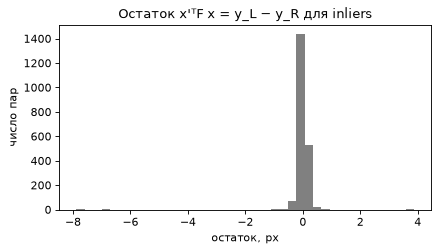

In [8]:
sift = cv2.SIFT_create()
kp_l, des_l = sift.detectAndCompute(left_gray, None)
kp_r, des_r = sift.detectAndCompute(right_gray, None)
good = [m for m, n in cv2.BFMatcher(cv2.NORM_L2).knnMatch(des_l, des_r, k=2) if m.distance < 0.7 * n.distance]
xl = np.float64([kp_l[m.queryIdx].pt for m in good]); xr = np.float64([kp_r[m.trainIdx].pt for m in good])

F_rect = np.array([[0, 0, 0], [0, 0, -1], [0, 1, 0]], dtype=float)
hom = lambda p: np.c_[p, np.ones(len(p))]
res_rect = np.einsum("ni,ij,nj->n", hom(xr), F_rect, hom(xl))          # x'ᵀ F x для каждой пары
print("пар после ratio test:", len(good))
print("проверка: x'ᵀF_rect x == y_L − y_R:", np.allclose(res_rect, xl[:, 1] - xr[:, 1]))

F_est, mask = cv2.findFundamentalMat(xl, xr, cv2.FM_RANSAC, 1.0, 0.999)
inl = mask.ravel().astype(bool)
lines = hom(xl) @ F_est.T                                               # эпиполярные линии на правом кадре
dist_est = np.abs(np.sum(lines * hom(xr), axis=1)) / np.hypot(lines[:, 0], lines[:, 1])

print(f"inliers RANSAC: {inl.sum()} из {len(inl)}")
print(f"F_rect, inliers : медиана |y_L−y_R| = {np.median(np.abs(res_rect[inl])):.3f} px, 95-й перцентиль = {np.percentile(np.abs(res_rect[inl]), 95):.3f} px")
print(f"F_rect, outliers: медиана |y_L−y_R| = {np.median(np.abs(res_rect[~inl])):.2f} px")
print(f"F оценённая, inliers: медианное расстояние до эпиполярной линии = {np.median(dist_est[inl]):.3f} px")
print("оценённая F (нормирована):\n", F_est / np.abs(F_est).max())
dsift = (xl[:, 0] - xr[:, 0])[inl]
print(f"disparity по SIFT-парам (inliers): 1-й..99-й перцентиль = {np.percentile(dsift, 1):.1f}..{np.percentile(dsift, 99):.1f} px; диапазон поиска стерео: {MIN_DISP}..{MIN_DISP + NUM_DISP}")
print(f"inliers с disparity вне диапазона 16..112: {int(((dsift < MIN_DISP) | (dsift > MIN_DISP + NUM_DISP)).sum())} (min = {dsift.min():.1f} px)")

plt.figure(figsize=(6, 3))
plt.hist(res_rect[inl], bins=40, color="gray")
plt.title("Остаток x'ᵀF x = y_L − y_R для inliers"); plt.xlabel("остаток, px"); plt.ylabel("число пар"); plt.show()

Остатки для верных пар — доли пикселя (медиана 0.07 px): соответствующие точки действительно лежат на одной строке, пара ректифицирована. У пар, отброшенных RANSAC, остаток — десятки пикселей: эпиполярное ограничение позволяет отбраковывать ошибки сопоставления.

Два замечания о пределах этой проверки.

- **Оценённая $F$ не совпала с $F_{rect}$ поэлементно**, хотя остатки с ней так же малы (0.10 px). Главная пара элементов $(2,3)$ и $(3,2)$ — противоположных знаков, как и должно быть, но остальные элементы не нулевые. Причина: сцена почти плоская (ткань занимает большую часть кадра), а для точек на одной плоскости $F$ определяется неоднозначно — данным одинаково хорошо удовлетворяет целое семейство матриц. Малый остаток не означает, что матрица найдена верно.
- **Ограничение ловит ошибки только поперёк эпиполярной линии.** Среди inliers есть две пары с disparity вне физически возможного диапазона (одна — с отрицательной, −47.6 px): неверное сопоставление, случайно попавшее на ту же строку. Узор ткани повторяется, и вдоль строки таких ложных кандидатов много.

## 5. Неудачные случаи

Посмотрим, **где** стереоалгоритм не дал ответа, и что происходит с глубиной на дальнем плане.

доля невалидных пикселей (SGBM, вне левой полосы):
  в 20 % самых бедных текстурой областей: 7.3 %
  в остальных                           : 12.2 %
  то же для BM: 32.7 % и 21.5 %
  рядом со скачками disparity (границы объектов): 27.4 %; вдали от них: 1.8 %

если disparity ошибается на 1 px:
  ближние 10 % пикселей (d≈67): ошибка глубины ≈ 6.64 см
  дальние 10 % пикселей (d≈23): ошибка глубины ≈ 54.77 см


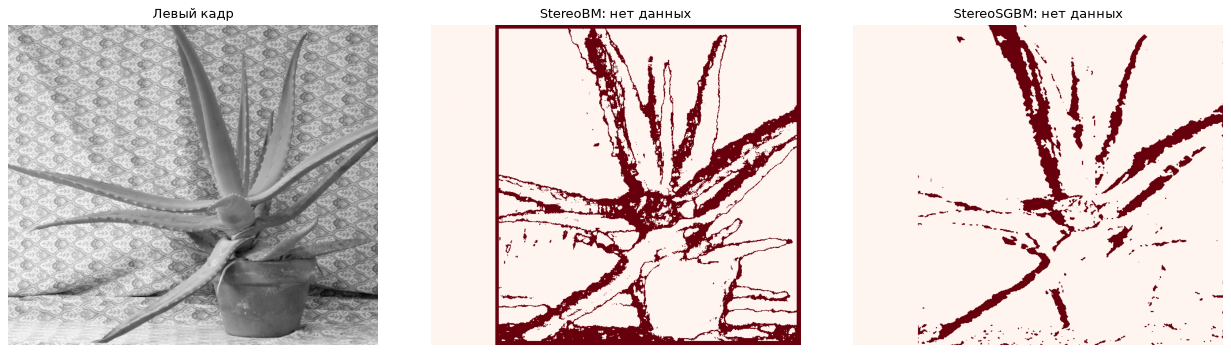

In [9]:
grad = cv2.GaussianBlur(np.abs(cv2.Sobel(left_gray, cv2.CV_32F, 1, 0, ksize=3)), (0, 0), 4)   # «количество текстуры»
region = np.zeros_like(valid); region[:, MIN_DISP + NUM_DISP:] = True
low_tex = grad < np.percentile(grad[region], 20)
print("доля невалидных пикселей (SGBM, вне левой полосы):")
print(f"  в 20 % самых бедных текстурой областей: {100 * (~valid)[region & low_tex].mean():.1f} %")
print(f"  в остальных                           : {100 * (~valid)[region & ~low_tex].mean():.1f} %")
print(f"  то же для BM: {100 * (~valid_bm)[region & low_tex].mean():.1f} % и {100 * (~valid_bm)[region & ~low_tex].mean():.1f} %")

# окклюзии: невалидные пиксели рядом с резким скачком disparity (границы листьев)
dfill = cv2.medianBlur(np.where(valid, disp, 0).astype(np.float32), 5)
jump = cv2.dilate((np.abs(cv2.Sobel(dfill, cv2.CV_32F, 1, 0, ksize=3)) > 40).astype(np.uint8), np.ones((1, 25), np.uint8)) > 0
print(f"  рядом со скачками disparity (границы объектов): {100 * (~valid)[region & jump].mean():.1f} %; вдали от них: {100 * (~valid)[region & ~jump].mean():.1f} %")

far = valid & (disp < np.quantile(dv, 0.1)); near = valid & (disp > np.quantile(dv, 0.9))
print(f"\nесли disparity ошибается на 1 px:")
print(f"  ближние 10 % пикселей (d≈{disp[near].mean():.0f}): ошибка глубины ≈ {fb / disp[near].mean() ** 2 * 100:.2f} см")
print(f"  дальние 10 % пикселей (d≈{disp[far].mean():.0f}): ошибка глубины ≈ {fb / disp[far].mean() ** 2 * 100:.2f} см")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
ax[0].imshow(left_gray); ax[0].set_title("Левый кадр")
ax[1].imshow(~valid_bm & region, cmap="Reds"); ax[1].set_title("StereoBM: нет данных")
ax[2].imshow(~valid & region, cmap="Reds"); ax[2].set_title("StereoSGBM: нет данных")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

Три вида отказов.

1. **Окклюзии — главный источник дыр.** Слева от каждого листа есть полоса фона, которую видит левая камера, но не видит правая — её закрывает сам лист. Пары для этих пикселей не существует. У SGBM рядом со скачками disparity (границы листьев) без ответа 27.4 % пикселей, вдали от них — только 1.8 %: почти все дыры SGBM — это окклюзии, их отбраковывает проверка согласованности лево-право (`disp12MaxDiff`).
2. **Слабая текстура — проблема блочного метода.** У BM в 20 % самых бедных текстурой областей без ответа 32.7 % пикселей против 21.5 % в остальных: окно на ровном участке похоже на любое соседнее, минимум функции сходства «плоский», и алгоритм отказывается отвечать. У SGBM такой зависимости нет (7.3 % против 12.2 %): требование плавности переносит ответ из текстурированных соседей. Оговорка: фон на этой паре — ткань с узором, по-настоящему пустых областей в кадре нет.
3. **Дальний план.** Алгоритм отвечает, но ответ неточен: ошибка в 1 px disparity на ближних листьях ($d\approx67$) — это ≈ 6.6 см глубины, на фоне ($d\approx23$) — ≈ 55 см, в 8 раз больше.

## 6. Вывод

- **Ручные расчёты:** $Z=2$ м; $\sigma_Z\approx0.167$ м при $d=18$; уменьшение disparity вдвое увеличивает чувствительность в 4 раза.
- **Одна и та же ошибка disparity даёт разную ошибку глубины.** Таблица шага 8–9: при ошибке ±1 px $|\Delta Z|$ растёт от 5.2 см у ближней точки ($d=75.6$ px, $Z\approx3.96$ м) до 56.7 см у дальней ($d=23$ px, $Z\approx13.0$ м). Глубины различаются в 3.29 раза, ошибки — в 10.8 раза, то есть ровно в $3.29^2$: зависимость квадратичная. Точки ложатся на теоретические кривые $fB/d^2$ и $Z^2/(fB)$.
- **Дальний план — самое слабое место стереозрения.** Disparity там мала, и та же погрешность сопоставления превращается в наибольшую погрешность расстояния. Улучшить это можно только увеличением $fB$: больше baseline или больше фокусное (разрешение).
- **BM и SGBM.** SGBM плотнее и чище: ≈ 88.7 % валидных пикселей при 0.5–0.9 % шумных, у BM — 72–79 % при 1.3–4.2 %. Увеличение блока у обоих методов снижает шум (BM: 4.15 % → 1.32 %; SGBM: 0.89 % → 0.47 %), но у BM при этом падает плотность (79.4 % → 72.3 %) и размываются тонкие листья. Слишком малый `numDisparities` даёт неверные значения для ближних объектов.
- **Эпиполярная проверка.** Для верных пар остаток $x'^TFx=y_L-y_R$ — медиана 0.07 px, 95 % меньше 0.26 px: пара ректифицирована. Для отброшенных пар — медиана ≈ 71 px.
- **Отказы:** окклюзии у границ объектов, слабая текстура (для BM), обрезанный диапазон disparity (раздел 5 и шаг 3–6).
- Абсолютные глубины в метрах иллюстративны: $f$ и $B$ для этой пары приняты условно. По условию можно использовать готовую ректифицированную пару, так что замена данных здесь не обязательна, но для реальных расстояний нужна калибровка.

## 7. Вопросы на защиту

**1. Почему глубина обратно пропорциональна disparity?**
Из подобия треугольников. Точка на глубине $Z$ со смещением $X$ от левой камеры проецируется в $x_L=fX/Z$, а в правой камере, сдвинутой на $B$, — в $x_R=f(X-B)/Z$. Разность: $d=x_L-x_R=fB/Z$. Чем дальше точка, тем меньше угол между лучами из двух камер и тем меньше сдвиг; для бесконечно далёкой точки лучи параллельны и $d=0$.

**2. Почему дальние объекты имеют существенно большую неопределённость глубины?**
$|dZ/dd|=fB/d^2=Z^2/(fB)$: чувствительность растёт как квадрат расстояния. Погрешность disparity примерно постоянна по кадру (доли пикселя — её задаёт алгоритм сопоставления), а вот её «цена» в метрах — нет. Вдвое дальше — вчетверо хуже. Геометрически: лучи от двух камер к далёкой точке почти параллельны, и точка их пересечения сильно смещается при малейшем изменении направления.

**3. Участок кода, где disparity переводится в depth, и обработка d≤0.**
`disp = compute(...) / 16.0` — убираем масштаб фиксированной точки. `valid = disp >= MIN_DISP` — маска пикселей, для которых пара найдена (при `minDisparity=0` это условие `disp > 0`; невалидные помечены как `minDisparity − 1`). `depth = np.full_like(disp, np.nan)` — по умолчанию «нет данных». `depth[valid] = F_PX * BASELINE_M / disp[valid]` — деление выполняется только для валидных пикселей. Без маски $d=0$ дало бы деление на ноль (бесконечность), а отрицательные значения — отрицательную глубину; NaN честно показывает, что расстояние неизвестно.